# 07 — Modèle Ensemble (PyTorch, Soft Voting)
**Objectif** : Combiner ResNet50 + VGG16 par vote pondéré (soft voting).
PyTorch : `torch.softmax` + combinaison linéaire des probabilités.


In [1]:
import sys; sys.path.append('../../src')
import torch, torch.nn as nn
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from data_loader import get_dataloaders
from models import ResNet50Transfer, VGG16Transfer
import warnings; warnings.filterwarnings('ignore')

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASSES = ['NORMAL', 'BACTERIA', 'VIRUS']
torch.manual_seed(42)

_, _, test_loader, *_ = get_dataloaders(
    '../../data/chest_xray/train', '../../data/chest_xray/val',
    '../../data/chest_xray/test', augment=False, batch_size=32)


Classes : {'NORMAL': 0, 'PNEUMONIA': 1}
Train   : 5216 | Val: 16 | Test: 624


In [2]:
# ── Charger les modèles ───────────────────────────────────────
def load_resnet():
    m = ResNet50Transfer(unfreeze_top=3).to(DEVICE)
    try:
        ckpt = torch.load('../../models/resnet50_best.pt', map_location=DEVICE)
        m.load_state_dict(ckpt['model_state'])
        print(f"ResNet50 chargé (val_acc={ckpt.get('val_acc',0):.4f})")
    except: print("ResNet50 : poids aléatoires (modèle non entraîné)")
    return m

model_resnet = load_resnet()
model_vgg    = VGG16Transfer().to(DEVICE)
print(f"VGG16    : {sum(p.numel() for p in model_vgg.parameters()):,} params")


ResNet50 : poids aléatoires (modèle non entraîné)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\takwa/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [07:11<00:00, 1.28MB/s] 


VGG16    : 21,138,755 params


In [3]:
# ── Prédictions individuelles ─────────────────────────────────
@torch.no_grad()
def get_probs(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    for imgs, labels in loader:
        probs = torch.softmax(model(imgs.to(DEVICE)), dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_labels.extend(labels.numpy())
    return np.array(all_probs), np.array(all_labels)

prob_resnet, y_true = get_probs(model_resnet, test_loader)
prob_vgg,    _      = get_probs(model_vgg,    test_loader)

acc_resnet = accuracy_score(y_true, prob_resnet.argmax(1))
acc_vgg    = accuracy_score(y_true, prob_vgg.argmax(1))
print(f"ResNet50 seul : {acc_resnet:.4f}")
print(f"VGG16    seul : {acc_vgg:.4f}")


ResNet50 seul : 0.0513
VGG16    seul : 0.3846


In [4]:
# ── Soft Voting — test de plusieurs pondérations ─────────────
weight_configs = {
    'Equal (0.5/0.5)':    (0.5, 0.5),
    'ResNet60 (0.6/0.4)': (0.6, 0.4),
    'ResNet70 (0.7/0.3)': (0.7, 0.3),
    'ResNet80 (0.8/0.2)': (0.8, 0.2),
}
ens_results = {}
for name, (wr, wv) in weight_configs.items():
    prob_ens = wr * prob_resnet + wv * prob_vgg
    acc      = accuracy_score(y_true, prob_ens.argmax(1))
    ens_results[name] = {'acc': acc, 'probs': prob_ens}
    print(f"{name:25s} → accuracy = {acc:.4f}")

best_ens = max(ens_results, key=lambda k: ens_results[k]['acc'])
print(f"\n✅ Meilleure pondération : {best_ens}  ({ens_results[best_ens]['acc']:.4f})")


Equal (0.5/0.5)           → accuracy = 0.3077
ResNet60 (0.6/0.4)        → accuracy = 0.2612
ResNet70 (0.7/0.3)        → accuracy = 0.2308
ResNet80 (0.8/0.2)        → accuracy = 0.1699

✅ Meilleure pondération : Equal (0.5/0.5)  (0.3077)



=== Rapport — Ensemble ===
              precision    recall  f1-score   support

      NORMAL       0.48      0.48      0.48       234
    BACTERIA       0.51      0.20      0.29       390
       VIRUS       0.00      0.00      0.00         0

    accuracy                           0.31       624
   macro avg       0.33      0.23      0.26       624
weighted avg       0.50      0.31      0.36       624



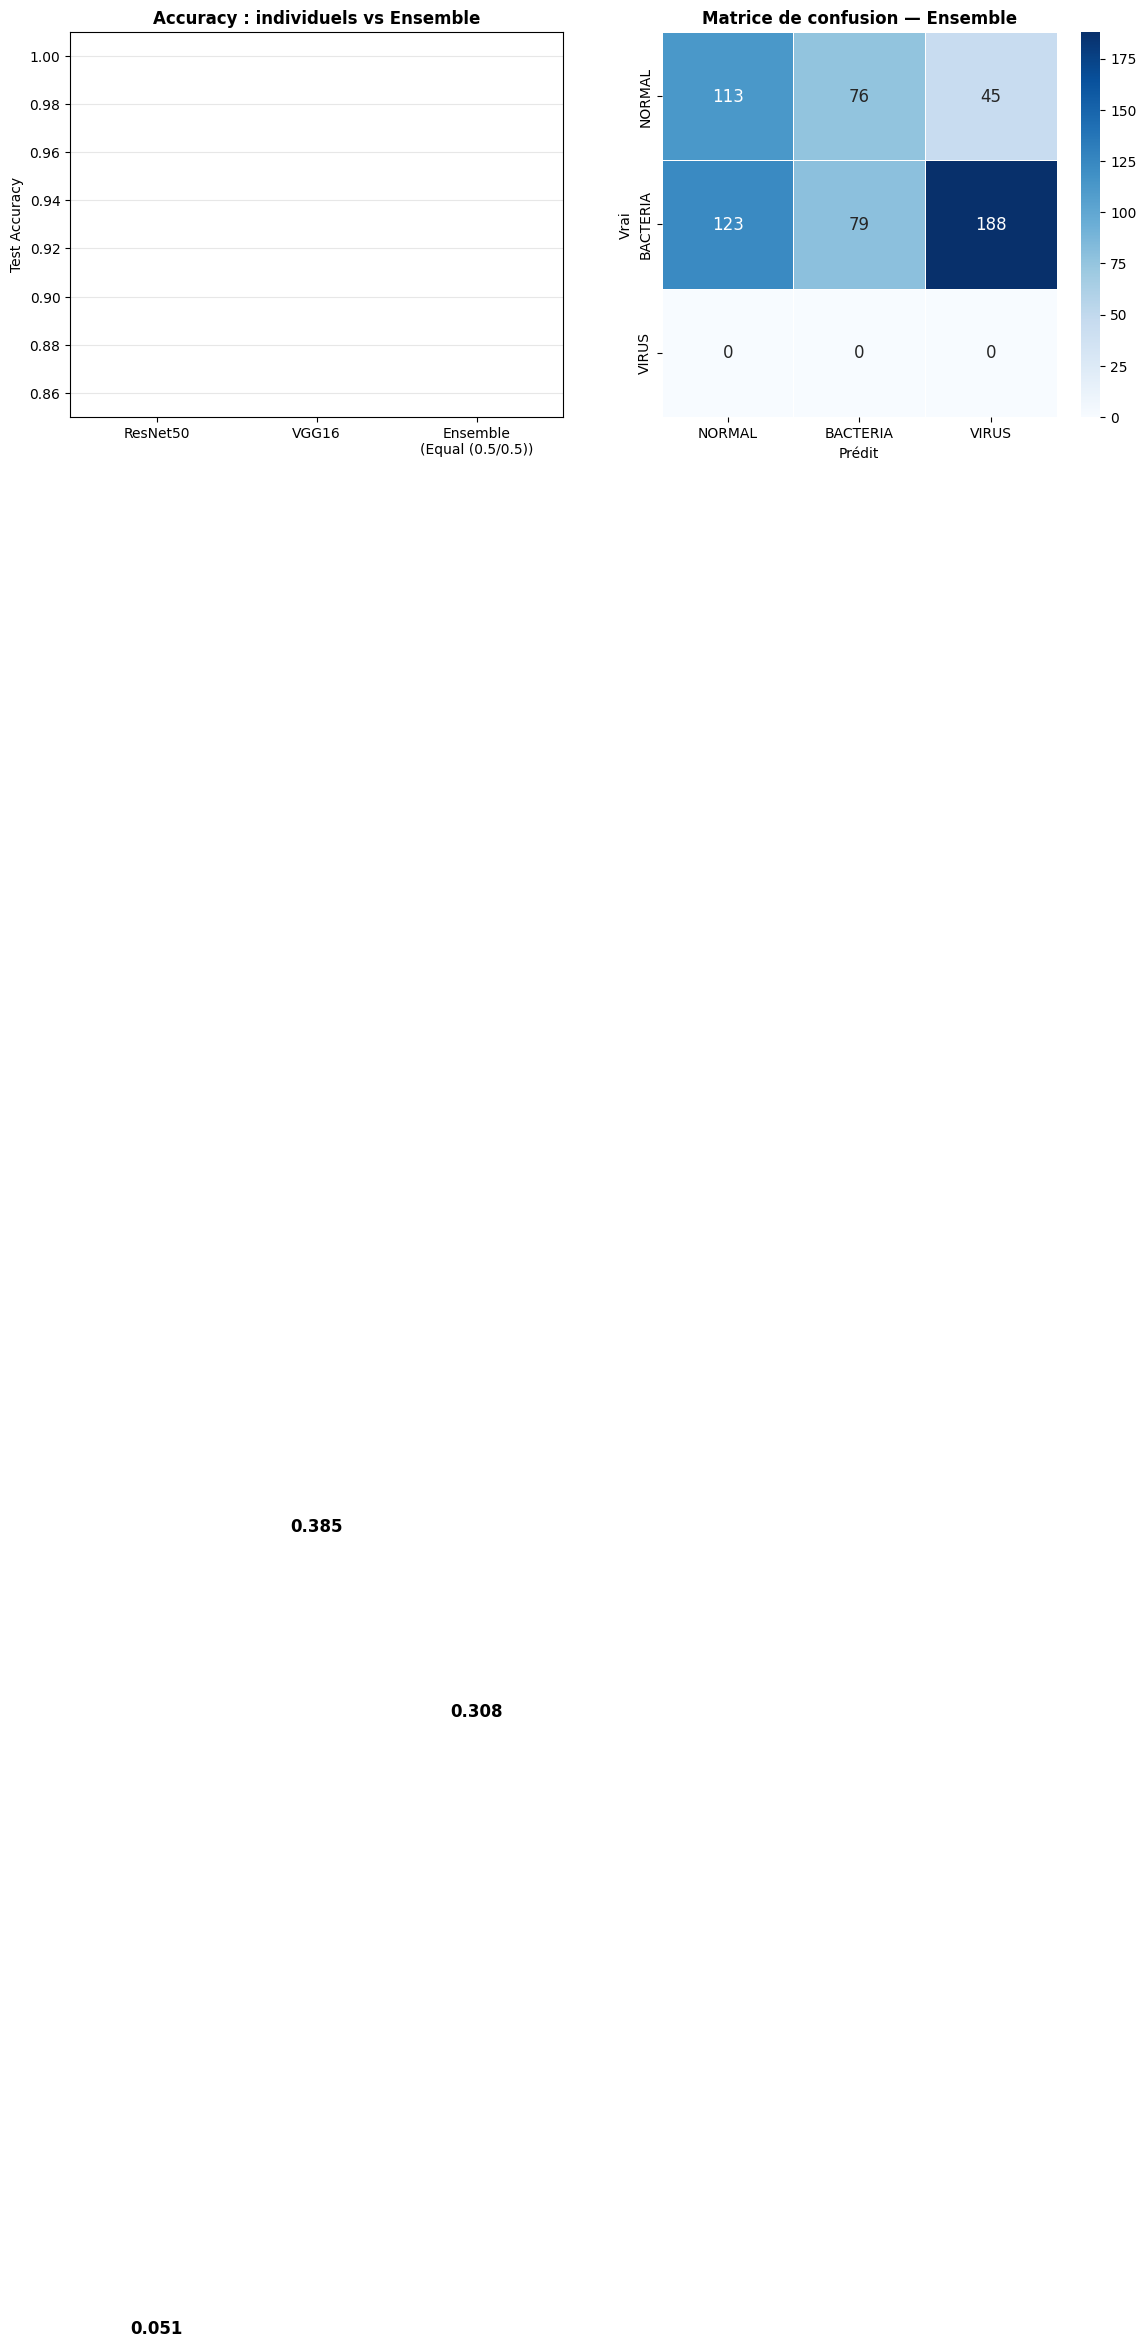

Gain ensemble vs ResNet seul : +25.6%


In [5]:
# ── Rapport + visualisation ──────────────────────────────────
best_preds = ens_results[best_ens]['probs'].argmax(1)
print("\n=== Rapport — Ensemble ===")
print(classification_report(y_true, best_preds, target_names=CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
all_acc = {'ResNet50': acc_resnet, 'VGG16': acc_vgg,
           f'Ensemble\n({best_ens})': ens_results[best_ens]['acc']}
bars = axes[0].bar(all_acc.keys(), all_acc.values(),
                   color=['#3498db','#e74c3c','#2ecc71'], edgecolor='white', linewidth=1.5)
axes[0].set_ylim(0.85, 1.01); axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Accuracy : individuels vs Ensemble', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, all_acc.values()):
    axes[0].text(bar.get_x()+bar.get_width()/2, acc+0.002, f'{acc:.3f}',
                 ha='center', fontsize=12, fontweight='bold')
cm = confusion_matrix(y_true, best_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1],
            linewidths=0.5, annot_kws={'size':12})
axes[1].set_title('Matrice de confusion — Ensemble', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Vrai'); axes[1].set_xlabel('Prédit')
plt.tight_layout(); plt.show()
print(f"Gain ensemble vs ResNet seul : +{(ens_results[best_ens]['acc']-acc_resnet)*100:.1f}%")
